<a href="https://colab.research.google.com/github/mrdhani282-wq/pengolahan_citra_digital/blob/main/Citra_Digital.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install pillow numpy matplotlib


#unggah gambar

In [ ]:

from google.colab import files

uploaded = files.upload()
nama_file = next(iter(uploaded))

print("Gambar berhasil diunggah:", nama_file)


Saving WhatsApp Image 2026-10-13 at 19.40.54.jpeg to WhatsApp Image 2026-10-13 at 19.40.54.jpeg
Gambar berhasil diunggah: WhatsApp Image 2026-10-13 at 19.40.54.jpeg


#ekstrak metadata gambar


In [ ]:

from PIL import Image, ExifTags
from pathlib import Path

gambar = Image.open(nama_file)

print("===== METADATA GAMBAR =====")
print("Nama file       :", nama_file)
print("Format          :", gambar.format)
print("Mode warna      :", gambar.mode)
print("Dimensi         :", gambar.size)
print("Lebar           :", gambar.width, "piksel")
print("Tinggi          :", gambar.height, "piksel")
print("Jumlah piksel   :", gambar.width * gambar.height)
print("Ukuran file     :", Path(nama_file).stat().st_size, "byte")

print("\n===== METADATA EXIF =====")
exif = gambar.getexif()

if exif:
    for tag, nilai in exif.items():
        nama_tag = ExifTags.TAGS.get(tag, str(tag))
        print(nama_tag, ":", nilai)
else:
    print("Metadata EXIF tidak tersedia.")


===== METADATA GAMBAR =====
Nama file       : WhatsApp Image 2026-10-13 at 19.40.54.jpeg
Format          : JPEG
Mode warna      : RGB
Dimensi         : (641, 633)
Lebar           : 641 piksel
Tinggi          : 633 piksel
Jumlah piksel   : 405753
Ukuran file     : 47628 byte

===== METADATA EXIF =====
Metadata EXIF tidak tersedia.


#membuktikan gambar tersusun dari angka

In [ ]:

import numpy as np

# Mengubah gambar menjadi RGB
gambar_rgb = gambar.convert("RGB")

# Mengubah gambar menjadi matriks angka
matriks = np.array(gambar_rgb)

print("===== PEMBUKTIAN PIXEL =====")
print("Bentuk matriks :", matriks.shape)
print("Tipe data      :", matriks.dtype)
print("Jumlah piksel  :", gambar.width * gambar.height)
print("Jumlah angka   :", matriks.size)
print("Nilai minimum  :", matriks.min())
print("Nilai maksimum :", matriks.max())

print("\n===== CONTOH NILAI RGB =====")

for y in range(5):
    for x in range(5):
        r, g, b = matriks[y, x]
        print(f"Pixel ({x},{y}) = R:{r}, G:{g}, B:{b}")

print("\n===== MATRIKS KANAL MERAH =====")
print(matriks[:5, :5, 0])


===== PEMBUKTIAN PIXEL =====
Bentuk matriks : (633, 641, 3)
Tipe data      : uint8
Jumlah piksel  : 405753
Jumlah angka   : 1217259
Nilai minimum  : 0
Nilai maksimum : 255

===== CONTOH NILAI RGB =====
Pixel (0,0) = R:18, G:18, B:18
Pixel (1,0) = R:19, G:19, B:19
Pixel (2,0) = R:22, G:22, B:22
Pixel (3,0) = R:25, G:25, B:25
Pixel (4,0) = R:28, G:28, B:28
Pixel (0,1) = R:10, G:10, B:10
Pixel (1,1) = R:11, G:11, B:11
Pixel (2,1) = R:12, G:12, B:12
Pixel (3,1) = R:14, G:14, B:14
Pixel (4,1) = R:16, G:16, B:16
Pixel (0,2) = R:7, G:7, B:7
Pixel (1,2) = R:7, G:7, B:7
Pixel (2,2) = R:7, G:7, B:7
Pixel (3,2) = R:7, G:7, B:7
Pixel (4,2) = R:8, G:8, B:8
Pixel (0,3) = R:11, G:11, B:11
Pixel (1,3) = R:10, G:10, B:10
Pixel (2,3) = R:10, G:10, B:10
Pixel (3,3) = R:10, G:10, B:10
Pixel (4,3) = R:10, G:10, B:10
Pixel (0,4) = R:11, G:11, B:11
Pixel (1,4) = R:11, G:11, B:11
Pixel (2,4) = R:11, G:11, B:11
Pixel (3,4) = R:11, G:11, B:11
Pixel (4,4) = R:12, G:12, B:12

===== MATRIKS KANAL MERAH =====
[[18 

#tampilan visualisasi piksel

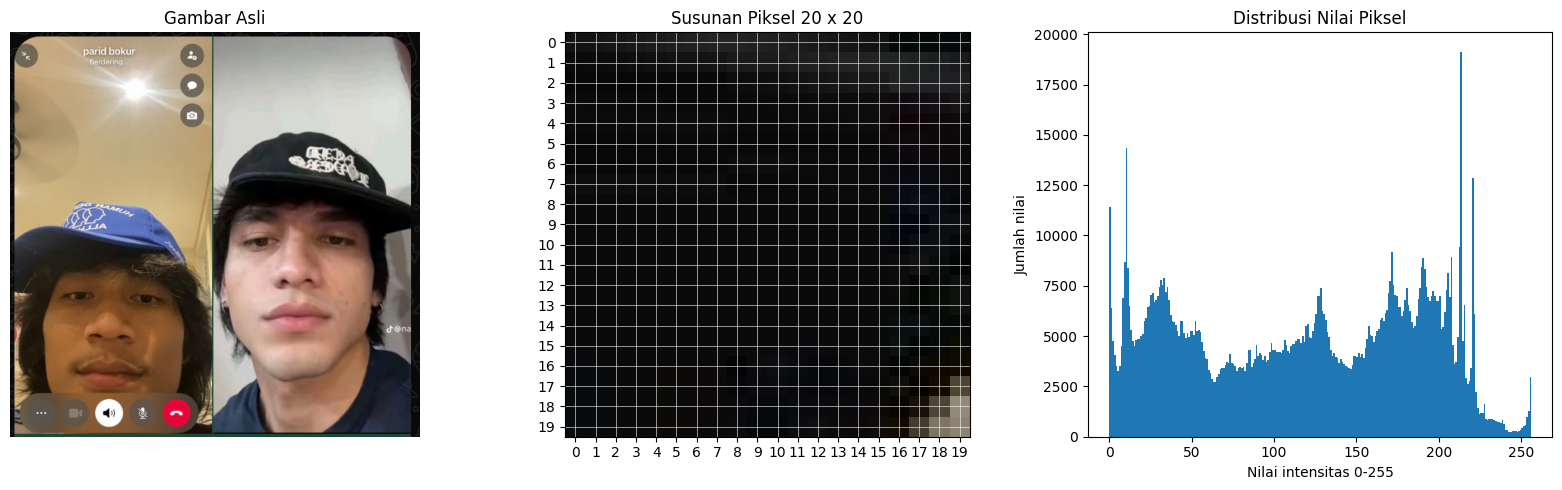

In [ ]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

# Gambar asli
ax[0].imshow(gambar_rgb)
ax[0].set_title("Gambar Asli")
ax[0].axis("off")

# Pembesaran piksel
ukuran = 20
ax[1].imshow(
    matriks[:ukuran, :ukuran],
    interpolation="nearest"
)
ax[1].set_title("Susunan Piksel 20 x 20")
ax[1].set_xticks(range(ukuran))
ax[1].set_yticks(range(ukuran))
ax[1].grid(color="white", linewidth=0.4)

# Histogram nilai RGB
ax[2].hist(matriks.ravel(), bins=256, range=(0, 256))
ax[2].set_title("Distribusi Nilai Piksel")
ax[2].set_xlabel("Nilai intensitas 0-255")
ax[2].set_ylabel("Jumlah nilai")

plt.tight_layout()
plt.show()


#simpan hasil matriks ke CSV

In [ ]:

# Menyimpan setiap kanal warna ke berkas CSV
np.savetxt("matriks_merah.csv", matriks[:, :, 0],
           delimiter=",", fmt="%d")

np.savetxt("matriks_hijau.csv", matriks[:, :, 1],
           delimiter=",", fmt="%d")

np.savetxt("matriks_biru.csv", matriks[:, :, 2],
           delimiter=",", fmt="%d")

print("Matriks berhasil disimpan.")

files.download("matriks_merah.csv")
files.download("matriks_hijau.csv")
files.download("matriks_biru.csv")


Matriks berhasil disimpan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>